# Fisheye Visual Odometry

Implement a visual odometry pipeline for fisheye drone footage that tracks features with Lucas–Kanade flow and recovers a relative camera trajectory.

This notebook only provides **data paths** and **trajectory evaluation**. The pipeline itself is up to you.

**Deliverables** (all in this notebook):
- Recovered relative trajectory, compared against GT with the evaluation cells below
- All code cells run and plots rendered
- Overlay video
- Summary markdown cell at the end: implementation choices, parameter tuning, observed trajectory quality

In [1]:
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

import json

from pose_helpers import (
    TrajectoryResult,
    TrajectoryVideoWriter,
    analyze_trajectory,
    draw_tracks,
    plot_trajectory,
    write_video_with_trajectory,
)

plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["font.size"] = 11

In [2]:
# --- Data paths ---
PROJECT_ROOT = Path("./flight")
VIDEO_PATH = PROJECT_ROOT / "recording.mp4"
CALIBRATION_PATH = PROJECT_ROOT / "calibration-params.json"
GT_PATH = PROJECT_ROOT / "flight_trajectory_coordinates.csv"

# --- Outputs ---
OVERLAY_VIDEO_PATH = Path("tracks_overlay.mp4")              # written by your pipeline: frames with your tracked points
TRAJECTORY_VIDEO_PATH = Path("tracks_with_trajectory.mp4")   # written by the evaluation: your overlay + trajectory plot

for p in (VIDEO_PATH, CALIBRATION_PATH, GT_PATH):
    if not p.exists():
        raise FileNotFoundError(p)

print(f"Video       : {VIDEO_PATH}")
print(f"Calibration : {CALIBRATION_PATH}")
print(f"Ground truth: {GT_PATH}")

Video       : flight/recording.mp4
Calibration : flight/calibration-params.json
Ground truth: flight/flight_trajectory_coordinates.csv


## Our Pipeline

In [3]:
data = json.loads(CALIBRATION_PATH.read_text())
camera_data = data["cameras"][0]
camera_data

{'distortionCoefficients': [-0.036787647748734414,
  0.004048026529406263,
  -0.007773661433555711,
  0.002068716240417432],
 'focalLengthX': 590.0679459329615,
 'focalLengthY': 589.5248066650331,
 'imageHeight': 1080,
 'imageWidth': 1920,
 'model': 'kannala-brandt4',
 'principalPointX': 1015.0660943015982,
 'principalPointY': 571.3563384482426}

In [4]:
H, W = camera_data["imageHeight"], camera_data["imageWidth"]
fx, fy = camera_data["focalLengthX"], camera_data["focalLengthY"]
cx, cy = camera_data["principalPointX"], camera_data["principalPointY"]

In [5]:
K = np.array([[fx, 0, cx],
              [0, fy, cy],
              [0, 0, 1]])
D = np.array(camera_data["distortionCoefficients"])
distortion_center = K[:, 2]  # principal point (cx, cy)

print("Camera matrix K:\n", K)
print("Distortion coefficients D:\n", D)
print("Distortion center:\n", distortion_center)

Camera matrix K:
 [[5.90067946e+02 0.00000000e+00 1.01506609e+03]
 [0.00000000e+00 5.89524807e+02 5.71356338e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Distortion coefficients D:
 [-0.03678765  0.00404803 -0.00777366  0.00206872]
Distortion center:
 [1.01506609e+03 5.71356338e+02 1.00000000e+00]


### Undistort image

(np.float64(-0.5), np.float64(1919.5), np.float64(1079.5), np.float64(-0.5))

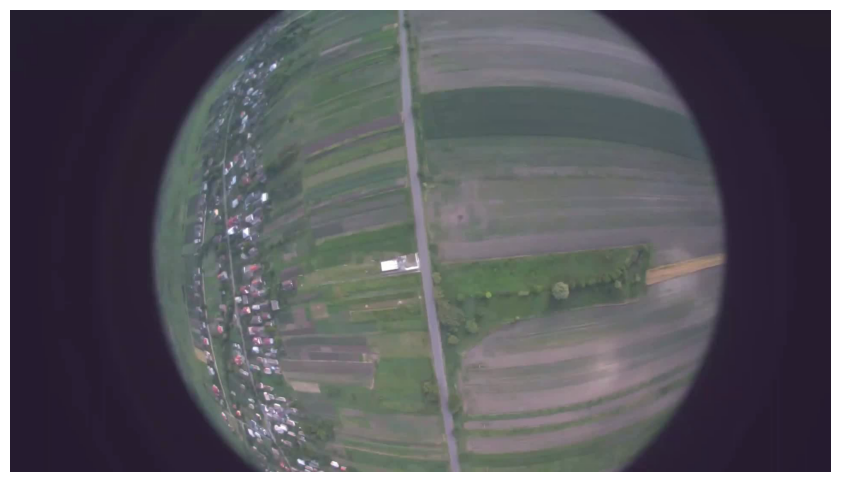

In [6]:
video = cv.VideoCapture(str(VIDEO_PATH))
ok, image = video.read()
assert ok, "frame read failed"
plt.imshow(image[..., ::-1]); plt.axis("off") # BGR to RGB

In [7]:
image.shape

(1080, 1920, 3)

Original K:  [[5.90067946e+02 0.00000000e+00 1.01506609e+03]
 [0.00000000e+00 5.89524807e+02 5.71356338e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
K_new:  [[5.90067946e+02 0.00000000e+00 1.01506609e+03]
 [0.00000000e+00 5.89524807e+02 5.71356338e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


(np.float64(-0.5), np.float64(1919.5), np.float64(1079.5), np.float64(-0.5))

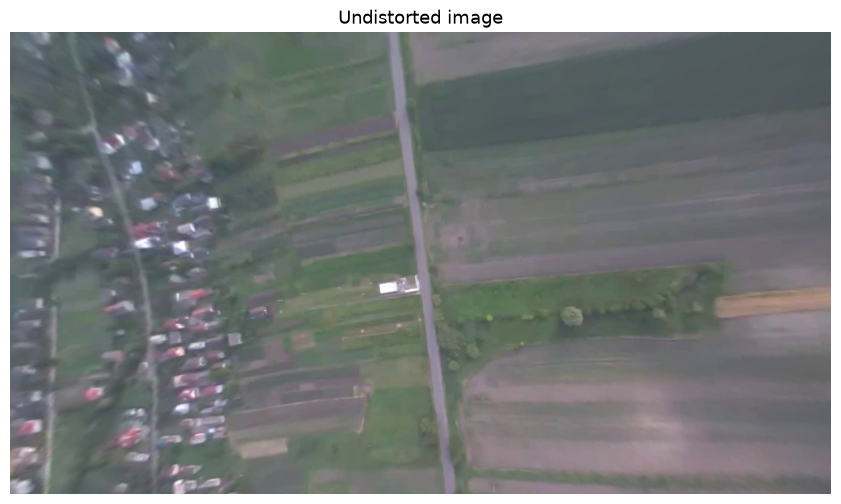

In [8]:
K_new = K.copy()
undistorted_image = cv.fisheye.undistortImage(image, K, D, Knew=K_new)
print("Original K: ", K)
print("K_new: ", K_new)
plt.imshow(undistorted_image[..., ::-1])   # BGR → RGB
plt.title("Undistorted image"); plt.axis("off")

max error: 3.1086244689504383e-15


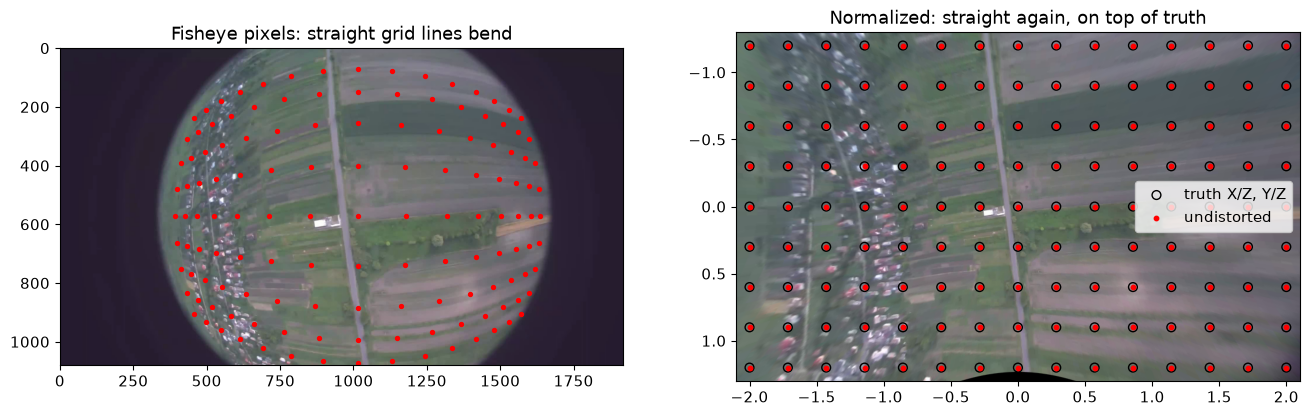

In [9]:
xs, ys = np.meshgrid(np.linspace(-2, 2, 15), np.linspace(-1.2, 1.2, 9))
obj = np.stack([xs.ravel(), ys.ravel(), np.ones(xs.size)], axis=1).reshape(-1, 1, 3)  # float64

img_pts, _ = cv.fisheye.projectPoints(obj, np.zeros(3), np.zeros(3), K, D)
norm = cv.fisheye.undistortPoints(img_pts, K, D)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
ax1.imshow(image[..., ::-1])
ax1.scatter(*img_pts.reshape(-1, 2).T, s=8, c="r",)
ax1.set_title("Fisheye pixels: straight grid lines bend")



H, W = image.shape[:2]
K_new = K.copy()
K_new[0, 0] *= 0.4; K_new[1, 1] *= 0.4          # smaller f → wider view
und = cv.fisheye.undistortImage(image, K, D, Knew=K_new, new_size=(W, H))

fx_new, fy_new, cx_new, cy_new = K_new[0, 0], K_new[1, 1], K_new[0, 2], K_new[1, 2]
extent = [(0 - cx_new) / fx_new, (W - cx_new) / fx_new,          # left, right
          (H - cy_new) / fy_new, (0 - cy_new) / fy_new]          # bottom, top

ax2.set_xlim(-2.1, 2.1)
ax2.set_ylim(1.3, -1.3)     # larger value first, so y keeps pointing down
ax2.imshow(und[..., ::-1], extent=extent)
# ...then your two scatter calls on ax2, as before
ax2.scatter(*obj[:, 0, :2].T, s=40, facecolors="none", edgecolors="k", label="truth X/Z, Y/Z")
ax2.scatter(*norm.reshape(-1, 2).T, s=10, c="r", label="undistorted")
ax2.set_aspect("equal"); ax2.legend()
ax2.set_title("Normalized: straight again, on top of truth")

print("max error:", np.abs(norm.reshape(-1, 2) - obj[:, 0, :2]).max())

In [10]:
def undistort_points(points: np.ndarray, K: np.ndarray, D: np.ndarray) -> np.ndarray:
    """Undistort points using fisheye model.

    Args:
        points: Nx2 array of distorted points (pixel coordinates).
        K: Camera matrix.
        D: Distortion coefficients.

    Returns:
        Nx2 array of undistorted points (pixel coordinates).
    """
    points = points.reshape(-1, 1, 2).astype(np.float64)
    undistorted = cv.fisheye.undistortPoints(points, K, D, P=K)
    return undistorted.reshape(-1, 2)

### Determining image circle
`T = 60` was chosen empirically

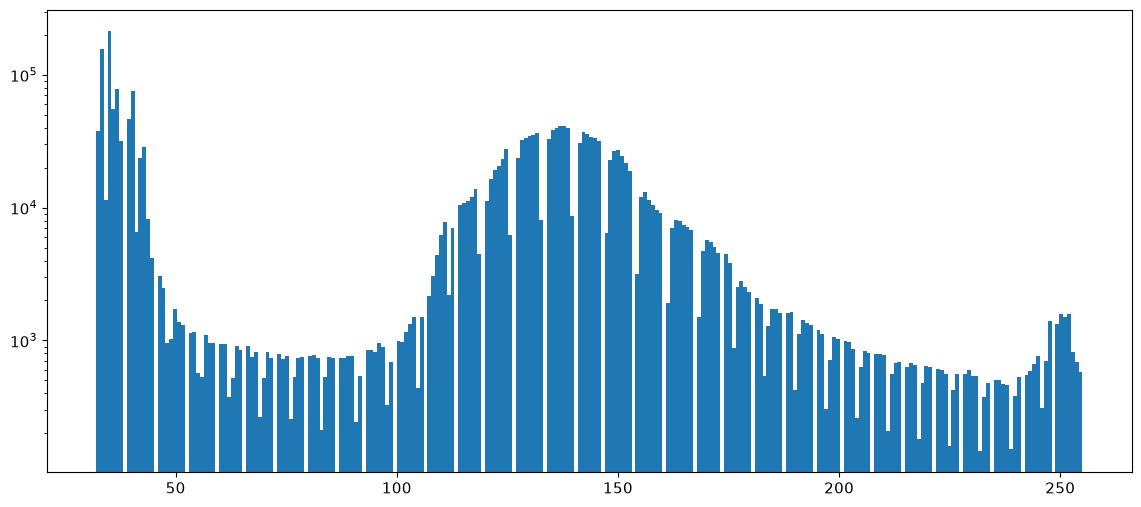

center=(1003.1, 555.9)  R=677.3  principal point=(1015.1, 571.4)


In [11]:
cap = cv.VideoCapture(str(VIDEO_PATH))
n = int(cap.get(cv.CAP_PROP_FRAME_COUNT))


acc = np.zeros((H, W), np.uint8)
for i in np.linspace(0, n - 1, 20, dtype=int):      # 20 frames spread over the video
    cap.set(cv.CAP_PROP_POS_FRAMES, int(i))
    ok, frame = cap.read()
    if not ok:
        continue
    gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    acc = np.maximum(acc, gray)                      # per-pixel brightest value seen
cap.release()

# Pick T from the data: look where the border values end and the scene begins
plt.hist(acc.ravel(), bins=256, log=True); plt.show()

T = 60
_, bw = cv.threshold(acc, T, 255, cv.THRESH_BINARY)

# Keep only the biggest blob, so a few stray bright pixels can't inflate the circle
contours, _ = cv.findContours(bw, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_NONE)
circle_contour = max(contours, key=cv.contourArea)
(xc, yc), R = cv.minEnclosingCircle(circle_contour)
print(f"center=({xc:.1f}, {yc:.1f})  R={R:.1f}  principal point=({K[0,2]:.1f}, {K[1,2]:.1f})")

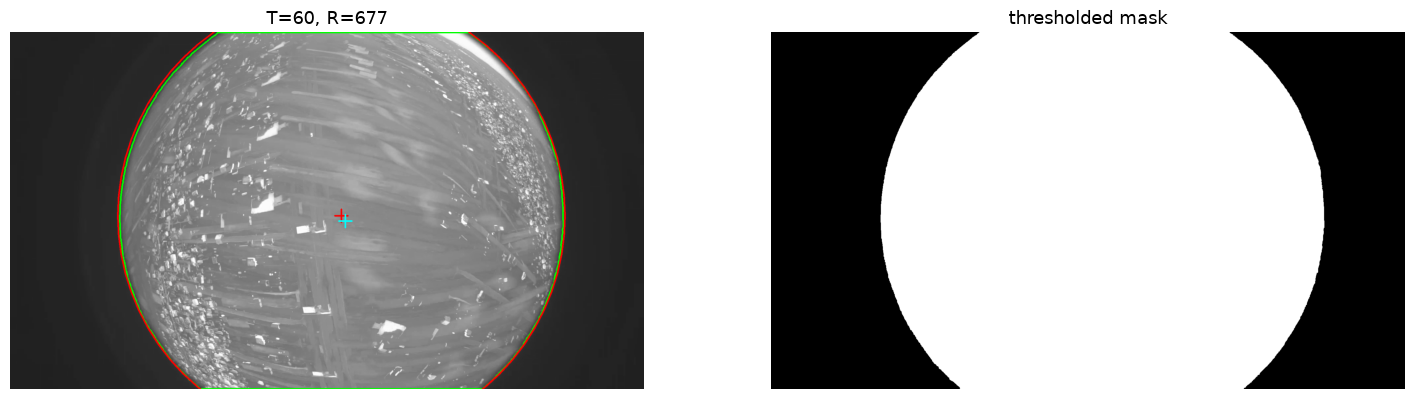

In [12]:
vis = cv.cvtColor(acc, cv.COLOR_GRAY2BGR)              # the max-image; swap in a real frame if you prefer
cv.drawContours(vis, [circle_contour], -1, (0, 255, 0), 3)          # green: the blob's outline
cv.circle(vis, (int(xc), int(yc)), int(R), (0, 0, 255), 3)          # red: enclosing circle
cv.drawMarker(vis, (int(xc), int(yc)), (0, 0, 255), cv.MARKER_CROSS, 40, 3)          # red +: circle center
cv.drawMarker(vis, (int(K[0, 2]), int(K[1, 2])), (255, 255, 0), cv.MARKER_CROSS, 40, 3)  # cyan +: principal point

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
ax1.imshow(vis[..., ::-1]); ax1.set_title(f"T={T}, R={R:.0f}"); ax1.axis("off")
ax2.imshow(bw, cmap="gray"); ax2.set_title("thresholded mask"); ax2.axis("off")
plt.show()

## Pipeline results

The evaluation below expects two things.

**1. A `traj_result: TrajectoryResult`** with:

| Field | Shape | Meaning |
| :-- | :-- | :-- |
| `positions` | `(N + 1, ≥2)` array | Row 0 is the starting pose; row `i + 1` is the pose at `frame_indices[i]`. Only X and Y are evaluated. |
| `frame_indices` | `N` ints | Absolute frame index in `recording.mp4` of each recovered pose (used to match GT rows). |
| `inliers` | `N` ints | Inlier count of the motion estimate for each recovered pose. |
| `timestamps` | `N` floats | Time of each recovered pose, in seconds. |

**2. An overlay video at `OVERLAY_VIDEO_PATH`** with one frame per frame of `recording.mp4`, in the same order (frame `k` of the overlay = frame `k` of the recording). `write_video_with_trajectory` seeks into it by `frame_indices`. `TrajectoryVideoWriter` and `draw_tracks` from `pose_helpers` can do this for you.

In [13]:
# Your pipeline here. It must produce `traj_result` and write OVERLAY_VIDEO_PATH.
traj_result: TrajectoryResult = ...

## Evaluation

Do not modify. Checks the result format, plots the trajectory and inliers, renders the trajectory video, and compares against GT.

In [14]:
assert isinstance(traj_result, TrajectoryResult), "traj_result must be a TrajectoryResult"
n = len(traj_result.frame_indices)
assert n > 0, "No poses recovered"
assert traj_result.positions.shape[0] == n + 1, "positions must have len(frame_indices) + 1 rows"
assert len(traj_result.inliers) == n and len(traj_result.timestamps) == n, "inliers/timestamps must match frame_indices"
assert OVERLAY_VIDEO_PATH.exists(), f"Overlay video not found: {OVERLAY_VIDEO_PATH}"
print(f"Recovered {n} poses")

plot_trajectory(traj_result)

AssertionError: traj_result must be a TrajectoryResult

In [ ]:
write_video_with_trajectory(
    OVERLAY_VIDEO_PATH,
    traj_result,
    output_path=TRAJECTORY_VIDEO_PATH,
    stride=5,
)

In [ ]:
analyze_trajectory(traj_result, GT_PATH)

## Summary

**Implementation choices:** _..._

**Parameter tuning:** _which parameters you tuned, what you tried, and the evidence from your run that justified the final values._

**Trajectory quality and overlay video:** _how close the result is to GT, where it drifts or fails, and why._